# 1. Import Libraries 

In [1]:
import os
import joblib
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = r"E:\UPI_Fraud_Detection"
MODEL_DIR = os.path.join(PROJECT_DIR, "xgboost_artifacts")

# Define artifact paths
model_path = os.path.join(MODEL_DIR, "xgboost_model.pkl")
preprocessor_path = os.path.join(
    MODEL_DIR, "xgboost_preprocessor.pkl"
)

# Load saved artifacts
xgb_model = joblib.load(model_path)
xgb_preprocessor = joblib.load(preprocessor_path)

print("XGBoost model loaded:", type(xgb_model).__name__)
print("Preprocessor loaded:", type(xgb_preprocessor).__name__)
print("Model directory exists:", os.path.exists(MODEL_DIR))
print("Both artifacts loaded successfully.")


XGBoost model loaded: XGBClassifier
Preprocessor loaded: ColumnTransformer
Model directory exists: True
Both artifacts loaded successfully.


# 2. Load the Trained XGBoost Model and Preprocessor

In [2]:
import joblib

xgb_preprocessor = joblib.load(preprocessor_path)

print("XGBoost model loaded:", type(xgb_model).__name__)
print("Preprocessor loaded:", type(xgb_preprocessor).__name__)
print("Both artifacts are ready.")

XGBoost model loaded: XGBClassifier
Preprocessor loaded: ColumnTransformer
Both artifacts are ready.


# 3. Load the Test Dataset.

In [24]:
PROCESSED_DIR = os.path.join(PROJECT_DIR, "data", "processed")

X_test = pd.read_csv(os.path.join(PROCESSED_DIR, "X_test.csv"))
y_test = pd.read_csv(os.path.join(PROCESSED_DIR, "y_test.csv"))

print("Test features shape:", X_test.shape)
print("Test labels shape:", y_test.shape)

print("\nTest feature columns:")
print(X_test.columns.tolist())

print("\nFraud label distribution:")
print(y_test.iloc[:, 0].value_counts())

Test features shape: (20000, 37)
Test labels shape: (20000, 1)

Test feature columns:
['payee_type', 'merchant_category', 'transaction_type', 'amount_inr', 'transaction_latitude', 'transaction_longitude', 'distance_from_home_km', 'hour_of_day', 'day_of_week', 'is_weekend', 'is_night', 'is_new_device', 'is_new_payee', 'payee_account_age_days', 'txns_last_1h', 'txns_last_24h', 'distinct_payees_last_24h', 'minutes_since_last_txn', 'historical_avg_amount', 'amount_to_avg_ratio', 'balance_before_inr', 'balance_drain_ratio', 'is_festival_period', 'festival_name', 'is_sale_day', 'sale_campaign', 'is_payday_period', 'is_offer_exposed', 'offer_type', 'is_power_outage', 'is_network_disruption', 'disruption_type', 'retry_count', 'payment_attempt_count', 'is_payment_retry', 'is_traveling', 'location_context']

Fraud label distribution:
is_fraud
0    19800
1      200
Name: count, dtype: int64


# 6. Verify Test Features Against Saved Model Features

In [25]:
feature_columns_path = os.path.join(
    MODEL_DIR, "xgboost_feature_columns.pkl"
)

feature_columns = joblib.load(feature_columns_path)

missing_columns = [
    col for col in feature_columns
    if col not in X_test.columns
]

extra_columns = [
    col for col in X_test.columns
    if col not in feature_columns
]

print("Saved model feature count:", len(feature_columns))
print("Test dataset feature count:", len(X_test.columns))
print("Missing columns:", missing_columns)
print("Extra columns:", extra_columns)

if not missing_columns and not extra_columns:
    X_test = X_test[feature_columns]
    print("\nFeature columns match successfully.")
else:
    print("\nFeature mismatch detected. Do not proceed yet.")

Saved model feature count: 37
Test dataset feature count: 37
Missing columns: []
Extra columns: []

Feature columns match successfully.


# 7. Verify Test Dataset and Preprocessor Compatibility

In [26]:
X_test_transformed = xgb_preprocessor.transform(X_test)

print("Original test shape:", X_test.shape)
print("Transformed test shape:", X_test_transformed.shape)

print("\nPreprocessing completed successfully.")

Original test shape: (20000, 37)
Transformed test shape: (20000, 69)

Preprocessing completed successfully.


# 8. Verify XGBoost Predictions on the Test Dataset

In [27]:
y_pred_proba = xgb_model.predict_proba(X_test_transformed)[:, 1]

print("Prediction probabilities generated successfully.")
print("Number of predictions:", len(y_pred_proba))
print("Minimum fraud probability:", y_pred_proba.min())
print("Maximum fraud probability:", y_pred_proba.max())
print("First 10 fraud probabilities:")
print(y_pred_proba[:10])

Prediction probabilities generated successfully.
Number of predictions: 20000
Minimum fraud probability: 1.1215518e-06
Maximum fraud probability: 0.9999902
First 10 fraud probabilities:
[1.8884114e-03 8.8744509e-06 5.1822071e-03 1.8459895e-04 1.3055458e-03
 8.3039785e-03 3.5256881e-04 1.8261471e-05 1.3855908e-03 7.3188647e-05]


# 9. Install and Import SHAP

In [10]:
# Install and Import SHAP

%pip install shap

import shap

print("SHAP version:", shap.__version__)
print("SHAP library imported successfully.")

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 8.9 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- --

# 10. Extract Transformed Feature Names

In [28]:
transformed_feature_names = xgb_preprocessor.get_feature_names_out()

print("Number of transformed feature names:", len(transformed_feature_names))
print("\nTransformed feature names:")

for i, feature in enumerate(transformed_feature_names, start=1):
    print(f"{i}. {feature}")

print("\nFeature count matches transformed dataset:",
      len(transformed_feature_names) == X_test_transformed.shape[1])

Number of transformed feature names: 69

Transformed feature names:
1. categorical__payee_type_Individual
2. categorical__payee_type_Merchant
3. categorical__merchant_category_Education
4. categorical__merchant_category_Entertainment
5. categorical__merchant_category_Food
6. categorical__merchant_category_Fuel
7. categorical__merchant_category_Grocery
8. categorical__merchant_category_Healthcare
9. categorical__merchant_category_Other
10. categorical__merchant_category_Personal
11. categorical__merchant_category_Shopping
12. categorical__merchant_category_Travel
13. categorical__merchant_category_Utilities
14. categorical__transaction_type_Collect_Request
15. categorical__transaction_type_Pay
16. categorical__festival_name_Akshaya Tritiya
17. categorical__festival_name_Eid al-Adha
18. categorical__festival_name_Ganesh Chaturthi
19. categorical__festival_name_Independence Day
20. categorical__festival_name_No festival
21. categorical__festival_name_Onam
22. categorical__festival_name_Ra

# 11. Create SHAP True Explainer

In [13]:
import shap

print("SHAP version:", shap.__version__)
print("SHAP imported successfully.")

SHAP version: 0.54.1
SHAP imported successfully.


In [15]:
explainer = shap.TreeExplainer(xgb_model)

print("SHAP Tree Explainer created successfully.")

SHAP Tree Explainer created successfully.


# 12. Select a Representation Test Sample

In [16]:
sample_size = min(1000, X_test_transformed.shape[0])

X_shap = X_test_transformed[:sample_size]

if hasattr(X_shap, "toarray"):
    X_shap = X_shap.toarray()

X_shap = np.asarray(X_shap)

print("SHAP sample shape:", X_shap.shape)

SHAP sample shape: (1000, 69)


# 13. Calculate SHAP Values

In [17]:
shap_values_raw = explainer.shap_values(X_shap)

# Handle different SHAP output formats
if isinstance(shap_values_raw, list):
    shap_values = shap_values_raw[1]
elif isinstance(shap_values_raw, np.ndarray) and shap_values_raw.ndim == 3:
    shap_values = shap_values_raw[:, :, 1]
else:
    shap_values = shap_values_raw

print("SHAP values calculated successfully.")
print("SHAP values shape:", shap_values.shape)

SHAP values calculated successfully.
SHAP values shape: (1000, 69)


# 12. Prepare SHAP Explanation Object

In [18]:
expected_value = explainer.expected_value

if isinstance(expected_value, (list, np.ndarray)):
    expected_value = np.asarray(expected_value).flatten()[1]

shap_explanation = shap.Explanation(
    values=shap_values,
    base_values=expected_value,
    data=X_shap,
    feature_names=transformed_feature_names
)

print("SHAP explanation object created successfully.")

SHAP explanation object created successfully.


# 13. Calculate Global Feature Importance

In [19]:
feature_importance = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Mean Absolute SHAP Value": np.abs(shap_values).mean(axis=0)
})

feature_importance = feature_importance.sort_values(
    by="Mean Absolute SHAP Value",
    ascending=False
).reset_index(drop=True)

print("Top 15 Most Influential Features:")
display(feature_importance.head(15))

Top 15 Most Influential Features:


,Feature,Mean Absolute SHAP Value
0,numerical__amount_to_avg_ratio,2.252161
1,numerical__distance_from_home_km,1.107829
2,numerical__hour_of_day,0.822664
3,categorical__transaction_type_Collect_Request,0.791216
4,numerical__is_new_payee,0.630602
5,numerical__payee_account_age_days,0.540598
6,numerical__balance_before_inr,0.489546
7,numerical__balance_drain_ratio,0.448843
8,numerical__minutes_since_last_txn,0.440495
9,numerical__transaction_latitude,0.429428


# 14. Visualize Global Feature Importance

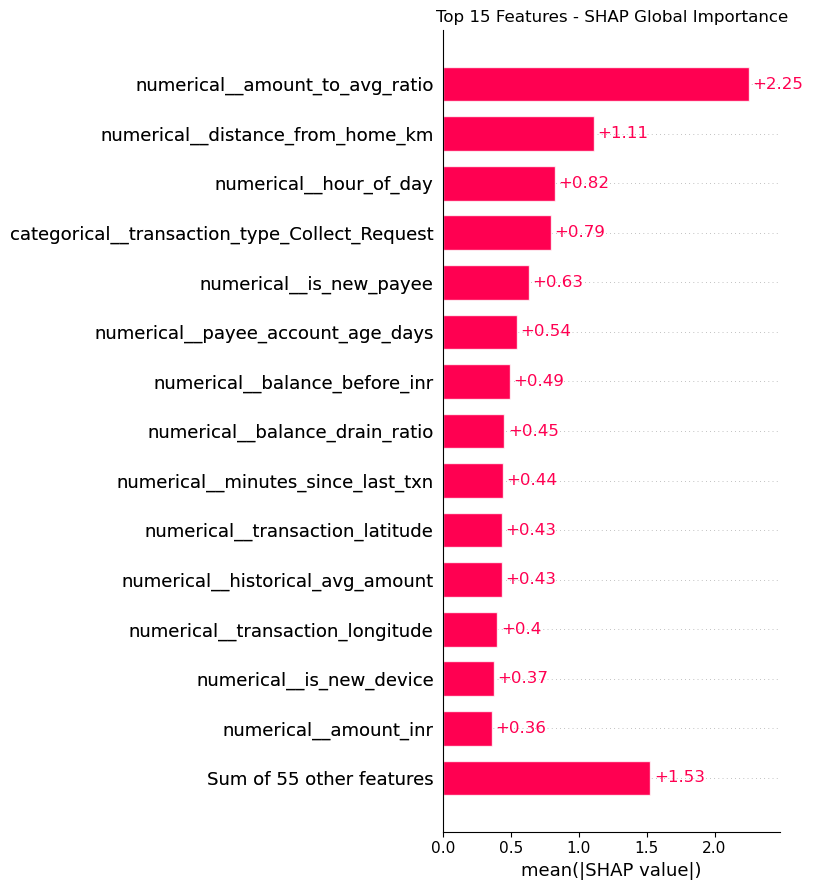

In [20]:
plt.figure(figsize=(10, 8))

shap.plots.bar(
    shap_explanation,
    max_display=15,
    show=False
)

plt.title("Top 15 Features - SHAP Global Importance")
plt.tight_layout()
plt.show()

# 15. Visualize SHAP Feature Impact

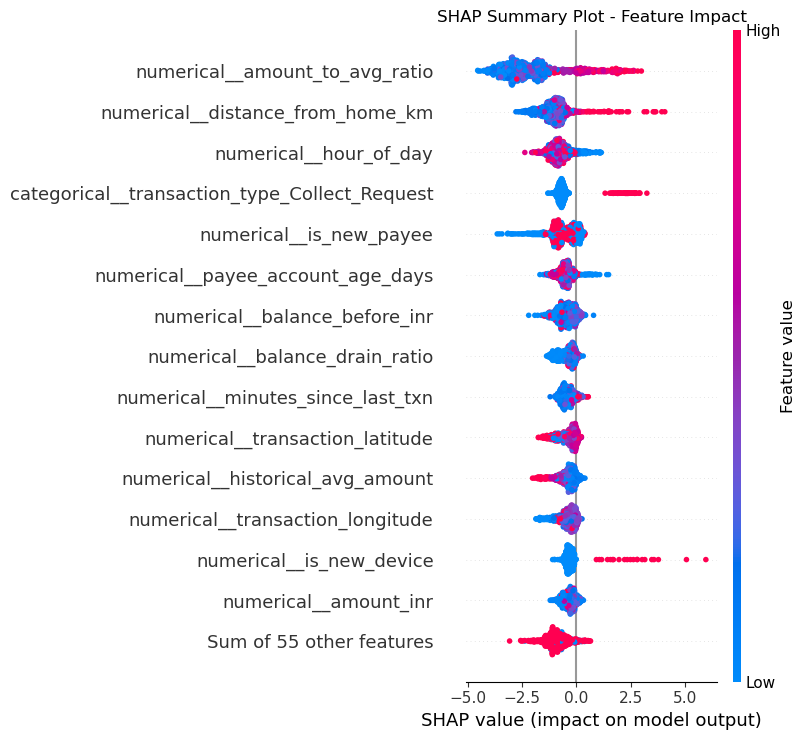

In [21]:
plt.figure(figsize=(10, 8))

shap.plots.beeswarm(
    shap_explanation,
    max_display=15,
    show=False
)

plt.title("SHAP Summary Plot - Feature Impact")
plt.tight_layout()
plt.show()

# 16. Analyze the Most Influential Feature

Most influential feature: numerical__amount_to_avg_ratio


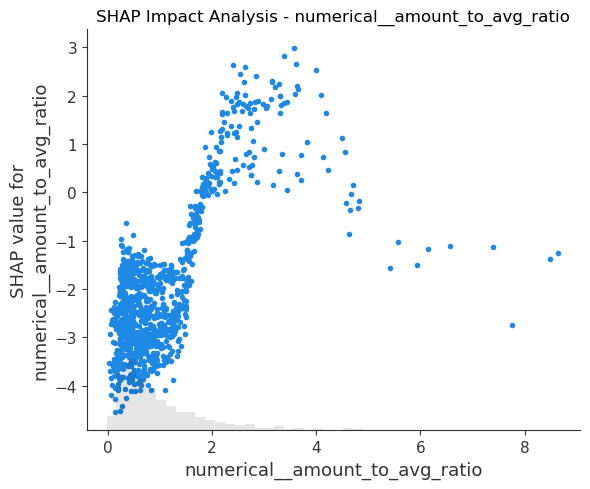

In [22]:
top_feature = feature_importance.iloc[0]["Feature"]

print("Most influential feature:", top_feature)

shap.plots.scatter(
    shap_explanation[:, top_feature],
    show=False
)

plt.title(f"SHAP Impact Analysis - {top_feature}")
plt.tight_layout()
plt.show()

# 17. Explain an Individual Fraud Prediction

Selected test transaction index: 939
Actual fraud label: 1
Predicted fraud probability: 0.9998609


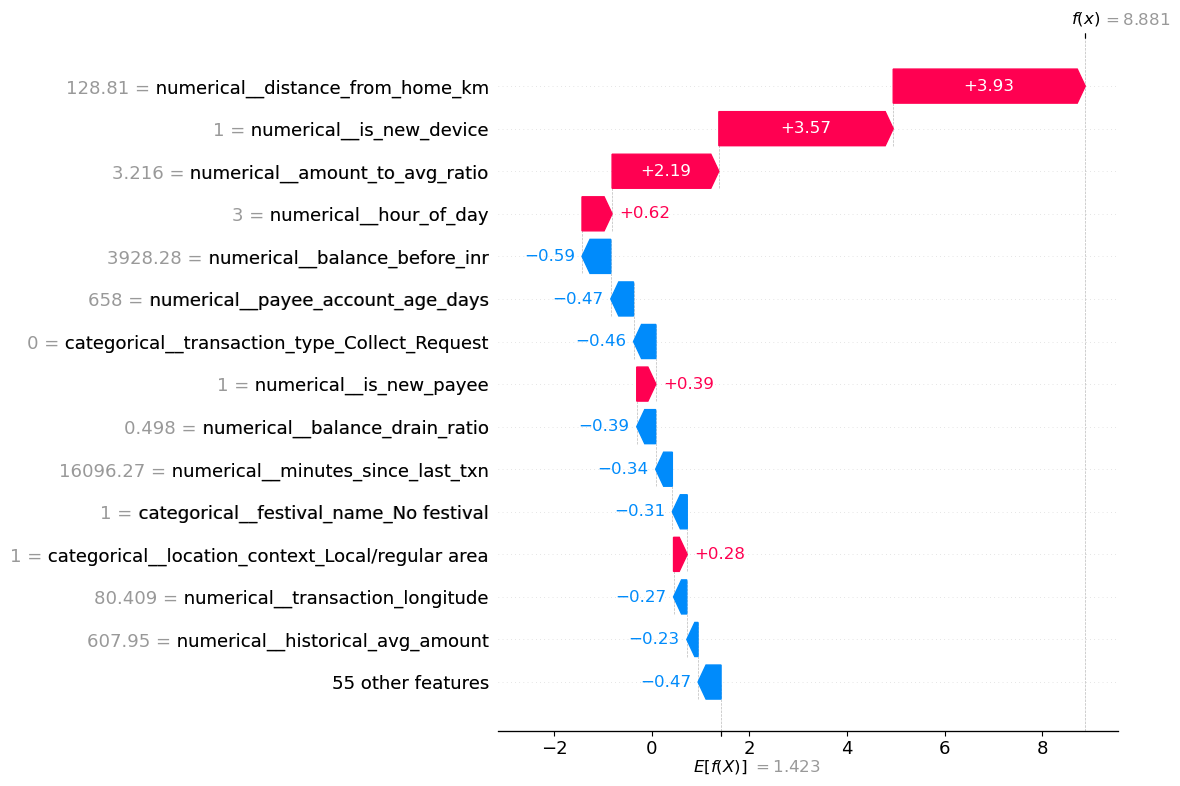

In [23]:
sample_probabilities = y_pred_proba[:sample_size]

local_index = int(np.argmax(sample_probabilities))

print("Selected test transaction index:", local_index)
print("Actual fraud label:", y_test.iloc[local_index, 0])
print("Predicted fraud probability:", sample_probabilities[local_index])

shap.plots.waterfall(
    shap_explanation[local_index],
    max_display=15
)